# code_176 · Candidate causal graphs and hidden common loading

**Book:** section 33.4. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_33_GUIDE.md), [execution evidence](../CHAPTER_33_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_176).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Treatments, estimands, observed versus simulator-only outcomes, fitting roles and independent assessment are declared below. Generated interventions do not establish causal identification from arbitrary operational logs or validate an individual counterfactual.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=6476;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 6476


<a id="equivalence-and-functional-assumptions"></a>
 ## Discover candidates without inventing a unique direction
 Generate 3,000 independent samples from X→Z→Ywith independent Gaussian disturbances. Test marginal and single-variable conditional correlations at alpha 0.01 to obtain a small skeleton. Enumerate all 25 three-node DAGs and compute their Gaussian BIC with freely estimated noise variances. Chain, reverse-chain and fork orientations share an observational factorization; their scores should agree up to numerical precision. A separate nonlinear additive-noise experiment fits degree-five polynomial regressions on 500 records and tests residual dependence on 300 held-out records using centered Gaussian-kernel HSIC and 99 permutations. The independence/functional assumptions are additional restrictions, not properties certified merely by a low regression error or p-value. This is a scoped original skeleton/enumeration/ANM experiment, not a complete PC implementation or LiNGAM replication.


,pair,condition_on,marginal_p,conditional_p
0,"[0, 1]",2,0.000000e+00,5.361826e-226
1,"[0, 2]",1,3.462433e-185,2.747786e-01
2,"[1, 2]",0,0.000000e+00,0.000000e+00


,direction,held_out_MSE,HSIC,permutation_p
0,X to Y,0.097991,0.000449,0.62
1,Y to X,0.042211,0.004481,0.01


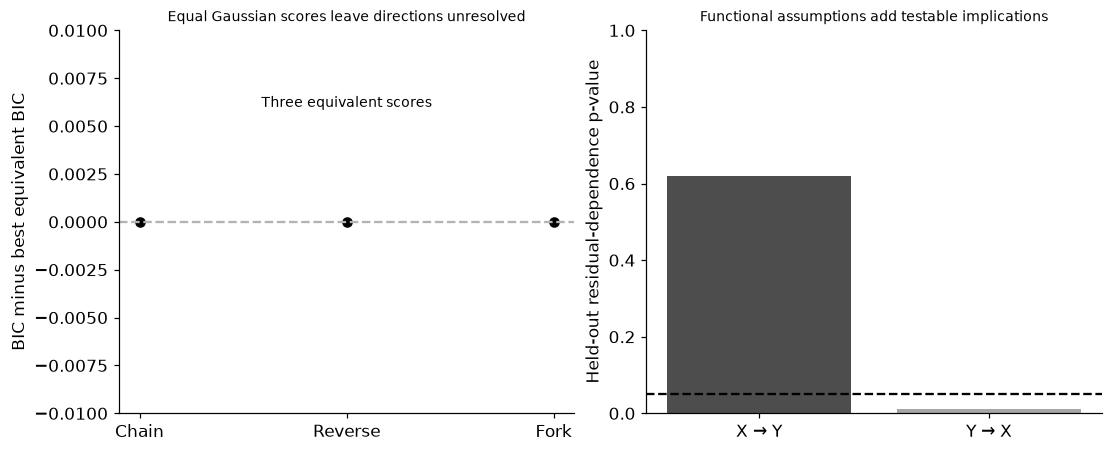

In [2]:
from scipy.stats import pearsonr,t as student_t
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
X=rng.normal(size=3000);Z=.9*X+rng.normal(size=3000);Y=.8*Z+rng.normal(size=3000);D=np.column_stack([X,Z,Y]);tests=[];skeleton=[]
for i,j in itertools.combinations(range(3),2):
    k=3-i-j;C=np.column_stack([np.ones(3000),D[:,k]]);ri=D[:,i]-C@np.linalg.lstsq(C,D[:,i],rcond=None)[0];rj=D[:,j]-C@np.linalg.lstsq(C,D[:,j],rcond=None)[0];marginal=float(pearsonr(D[:,i],D[:,j]).pvalue);partial_r=float(pearsonr(ri,rj).statistic);conditional=float(2*student_t.sf(abs(partial_r)*np.sqrt(2997/max(1e-15,1-partial_r**2)),df=2997));tests.append({'pair':[i,j],'condition_on':k,'marginal_p':marginal,'conditional_p':conditional});
    if marginal<.01 and conditional<.01:skeleton.append([i,j])
pairs=[(i,j) for i in range(3) for j in range(3) if i!=j];dags=[]
def acyclic(edges):return any(all(order.index(i)<order.index(j) for i,j in edges) for order in itertools.permutations(range(3)))
def bic(edges):
    score=0.
    for node in range(3):
        parents=[i for i,j in edges if j==node];design=np.column_stack([np.ones(3000),D[:,parents]]);res=D[:,node]-design@np.linalg.lstsq(design,D[:,node],rcond=None)[0];score+=3000*np.log(np.mean(res**2))+(2+len(parents))*np.log(3000)
    return float(score)
for bits in itertools.product([0,1],repeat=6):
    edges=[edge for edge,bit in zip(pairs,bits) if bit]
    if acyclic(edges):dags.append({'edges':[list(e) for e in edges],'BIC':bic(edges)})
equivalent=[[(0,1),(1,2)],[(2,1),(1,0)],[(1,0),(1,2)]];eq_scores=[bic(e) for e in equivalent];assert len(dags)==25;np.testing.assert_allclose(eq_scores,eq_scores[0],atol=1e-9)
axx=rng.uniform(-2,2,800);ayy=.8*axx+axx**3+rng.normal(0,.3,800);anm=[]
def kernel_center(v):
    distance=(v[:,None]-v[None,:])**2;bw=np.median(distance[distance>0]);K=np.exp(-distance/(2*bw));return K-K.mean(0)[None,:]-K.mean(1)[:,None]+K.mean()
for label,a,b in [('X to Y',axx,ayy),('Y to X',ayy,axx)]:
    model=make_pipeline(PolynomialFeatures(5,include_bias=False),StandardScaler(),Ridge(alpha=1e-6)).fit(a[:500,None],b[:500]);res=b[500:]-model.predict(a[500:,None]);K=kernel_center(a[500:]);L=kernel_center(res);observed=float(np.sum(K*L)/(299**2));null=[];prng=np.random.default_rng(SEED+10)
    for repeat in range(99):idx=prng.permutation(300);null.append(float(np.sum(K*L[np.ix_(idx,idx)])/(299**2)))
    anm.append({'direction':label,'held_out_MSE':float(np.mean(res**2)),'HSIC':observed,'permutation_p':float((1+np.sum(np.array(null)>=observed))/100)})
RESULTS.update(gaussian_records=3000,variable_order=['X','Z','Y'],conditional_tests=tests,skeleton=skeleton,DAGs=dags,equivalent_orientation_BIC=eq_scores,ANM=anm,ANM_fit_records=500,ANM_test_records=300,HSIC_permutations=99,full_PC_or_LiNGAM_replication=False);display(pd.DataFrame(tests));display(pd.DataFrame(anm));fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].scatter(range(3),np.array(eq_scores)-min(eq_scores),color='black',s=35);axes[0].axhline(0,color='.7',linestyle='--');axes[0].text(.5,.8,'Three equivalent scores',ha='center',transform=axes[0].transAxes,fontsize=9);axes[0].set(xticks=range(3),xticklabels=['Chain','Reverse','Fork'],ylabel='BIC minus best equivalent BIC',ylim=(-.01,.01),title='Equal Gaussian scores leave directions unresolved');axes[1].bar(range(2),[r['permutation_p'] for r in anm],color=['.3','.65']);axes[1].axhline(.05,color='black',linestyle='--');axes[1].set(xticks=[0,1],xticklabels=['X → Y','Y → X'],ylabel='Held-out residual-dependence p-value',ylim=(0,1),title='Functional assumptions add testable implications');plt.show()


<a id="lag-prediction-with-hidden-loading"></a>
 ## Temporal prediction does not eliminate common causes
 A hidden loading process Uevolves autoregressively. SensorXat a time measures that loading; responseYat the next time measures the previous loading. There is no structural X→Yarrow. Fit a lagged Y-only predictor and a Y-plus-X-lag predictor on 700 earlier records; evaluate on 300 later records. Then expose the previously hidden loading in a declared oracle-control comparison and inspect the conditionalXcoefficient. The intervention do(X=x)changes the sensor reading, not the latent load that drivesY. A predictive gain or temporal ordering therefore does not alone prove a physical effect of changing that sensor. No future records choose the predictor or enter its fitting.


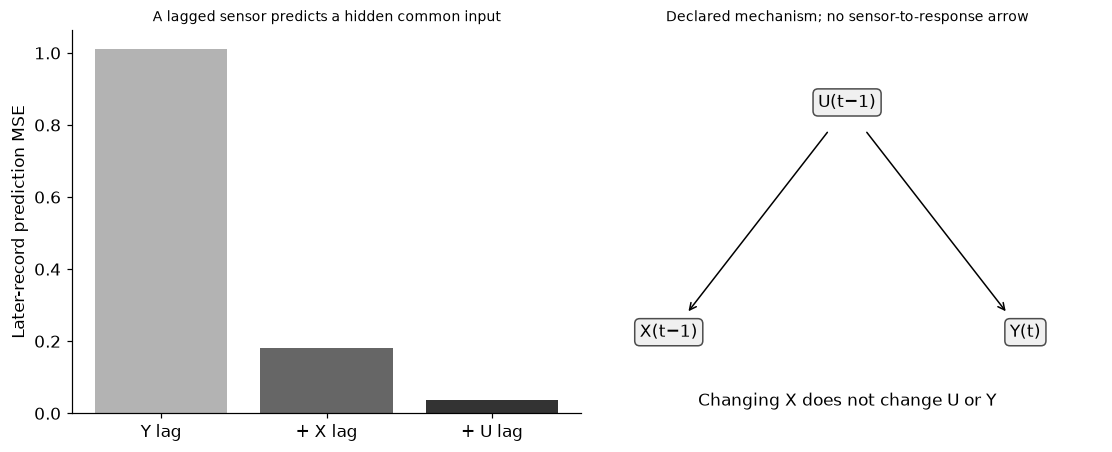

In [3]:
U=np.zeros(1101)
for t in range(1,1101):U[t]=.8*U[t-1]+rng.normal()
sensor=U+rng.normal(0,.4,1101);response=np.r_[0,U[:-1]]+rng.normal(0,.2,1101);idx=np.arange(101,1101);target=response[idx];y_lag=response[idx-1];x_lag=sensor[idx-1];u_lag=U[idx-1];designs={'Y lag':np.column_stack([np.ones(1000),y_lag]),'Y + X lag':np.column_stack([np.ones(1000),y_lag,x_lag]),'Y + X + U lag':np.column_stack([np.ones(1000),y_lag,x_lag,u_lag])};temporal=[]
for name,design in designs.items():
    coef=np.linalg.lstsq(design[:700],target[:700],rcond=None)[0];prediction=design[700:]@coef;temporal.append({'predictor':name,'future_MSE':float(np.mean((prediction-target[700:])**2)),'X_lag_coefficient':float(coef[2]) if design.shape[1]>=3 else None})
assert len(target)==1000 and len(temporal)==3 and np.isfinite([r['future_MSE'] for r in temporal]).all()
RESULTS.update(temporal_fit_records=700,temporal_final_records=300,temporal_prediction=temporal,true_sensor_intervention_effect=0.,hidden_common_loading=True)
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(3),[r['future_MSE'] for r in temporal],color=['.7','.4','.2']);axes[0].set(xticks=range(3),xticklabels=['Y lag','+ X lag','+ U lag'],ylabel='Later-record prediction MSE',title='A lagged sensor predicts a hidden common input');axes[1].axis('off');pos={'U(t−1)':(.5,.8),'X(t−1)':(.15,.2),'Y(t)':(.85,.2)}
for label,(x,y) in pos.items():axes[1].text(x,y,label,ha='center',transform=axes[1].transAxes,bbox={'boxstyle':'round','facecolor':'.94','edgecolor':'.3'})
for a,b in [('U(t−1)','X(t−1)'),('U(t−1)','Y(t)')]:
    start=np.array(pos[a]);end=np.array(pos[b]);v=end-start;axes[1].annotate('',xy=end-.1*v,xytext=start+.1*v,xycoords='axes fraction',arrowprops={'arrowstyle':'->'})
axes[1].text(.5,.02,'Changing X does not change U or Y',ha='center',transform=axes[1].transAxes);axes[1].set_title('Declared mechanism; no sensor-to-response arrow');plt.show()


In [4]:
summary={'example_id':'code_176','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual Gaussian conditional-correlation skeleton tests', 'all 25 three-node DAGs scored with free-variance Gaussian BIC', 'Markov-equivalent orientations retained', 'held-out nonlinear additive-noise regression and kernel residual-dependence permutation tests', 'temporal predictive gain under a hidden common cause separated from intervention effect'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual Gaussian conditional-correlation skeleton tests", "all 25 three-node DAGs scored with free-variance Gaussian BIC", "Markov-equivalent orientations retained", "held-out nonlinear additive-noise regression and kernel residual-dependence permutation tests", "temporal predictive gain under a hidden common cause separated from intervention effect"], "elapsed_seconds": 0.624, "example_id": "code_176", "hardware": "Darwin arm64 CPU", "results": {"ANM": [{"HSIC": 0.0004486816610743091, "direction": "X to Y", "held_out_MSE": 0.09799123622132133, "permutation_p": 0.62}, {"HSIC": 0.0044814146895537, "direction": "Y to X", "held_out_MSE": 0.042211363226837356, "permutation_p": 0.01}], "ANM_fit_records": 500, "ANM_test_records": 300, "DAGs": [{"BIC": 4183.776982714109, "edges": []}, {"BIC": 1805.3983255862504, "edges": [[2, 1]]}, {"BIC": 3348.801689174522, "edges": [[2, 0]]}, {"BIC": 970.4230320466629, "edges": [[2, 0], [2, 1]]}, {"BIC": 180